<a href="https://colab.research.google.com/github/Meghakoranga/OnlineRetailAnalysis/blob/main/OnlineRetailAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [45]:
import pandas as pd
!pip install ucimlrepo

In [46]:
from ucimlrepo import fetch_ucirepo
online_retail=fetch_ucirepo(id=352)
df=online_retail.data.original

In [47]:
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [48]:
print(df.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [49]:
print(online_retail.variables[["name","role","type","description"]])

          name     role         type  \
0    InvoiceNo       ID  Categorical   
1    StockCode       ID  Categorical   
2  Description  Feature  Categorical   
3     Quantity  Feature      Integer   
4  InvoiceDate  Feature         Date   
5    UnitPrice  Feature   Continuous   
6   CustomerID  Feature  Categorical   
7      Country  Feature  Categorical   

                                         description  
0  a 6-digit integral number uniquely assigned to...  
1  a 5-digit integral number uniquely assigned to...  
2                                       product name  
3  the quantities of each product (item) per tran...  
4  the day and time when each transaction was gen...  
5                             product price per unit  
6  a 5-digit integral number uniquely assigned to...  
7  the name of the country where each customer re...  


In [50]:
df_raw=df.copy()  #backup

In [51]:
print("dataset shape:",df.shape)
df.head()
df.info()
df.describe(include="all")

dataset shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/2011 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


In [52]:
missing_values=df.isnull().sum()
print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [53]:
duplicate_count=df.duplicated().sum()
print("duplicate rows:",duplicate_count)


duplicate rows: 5268


In [54]:
df=df.drop_duplicates().copy()
print("shape after removing duplicates :", df.shape)

shape after removing duplicates : (536641, 8)


In [55]:
cancellations=df[df["InvoiceNo"].astype(str).str.startswith("C")].copy()
print("Cancellation records:",len(cancellations))

Cancellation records: 9251


In [56]:
sales=df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()

In [57]:
sales=sales[(sales["Quantity"]>0)&(sales["UnitPrice"]>0)].copy()

In [58]:
df_clean = sales.dropna(subset=["Description"]).copy()

In [59]:
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"]
)

In [60]:
customer_data = df_clean.dropna(
    subset=["CustomerID"]
).copy()

In [61]:
print("\nOriginal shape:", df_raw.shape)
print("Cleaned sales shape:", df_clean.shape)
print("Customer data shape:", customer_data.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nRemaining duplicates:", df_clean.duplicated().sum())


Original shape: (541909, 8)
Cleaned sales shape: (524878, 8)
Customer data shape: (392692, 8)

Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
dtype: int64

Remaining duplicates: 0


In [62]:
df_clean.to_csv("Online_Retail_Cleaned.csv",index=False)

In [63]:
# Module 2 : Expolaratory Data Analysis (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
df_clean["Revenue"]=(df_clean["Quantity"]* df_clean["UnitPrice"])
df_clean[["Description","Quantity","UnitPrice","Revenue"]].head()

,Description,Quantity,UnitPrice,Revenue
0,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,WHITE METAL LANTERN,6,3.39,20.34
2,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34


In [65]:
print("total Revenue:",df_clean["Revenue"].sum())

total Revenue: 10642110.804000001



Monthly Revenue:
      Month     Revenue
0   2010-12   821452.73
1   2011-01   689811.61
2   2011-02   522545.56
3   2011-03   716215.26
4   2011-04   536968.49
5   2011-05   769296.61
6   2011-06   760547.01
7   2011-07   718076.12
8   2011-08   757841.38
9   2011-09  1056435.19
10  2011-10  1151263.73
11  2011-11  1503866.78
12  2011-12   637790.33


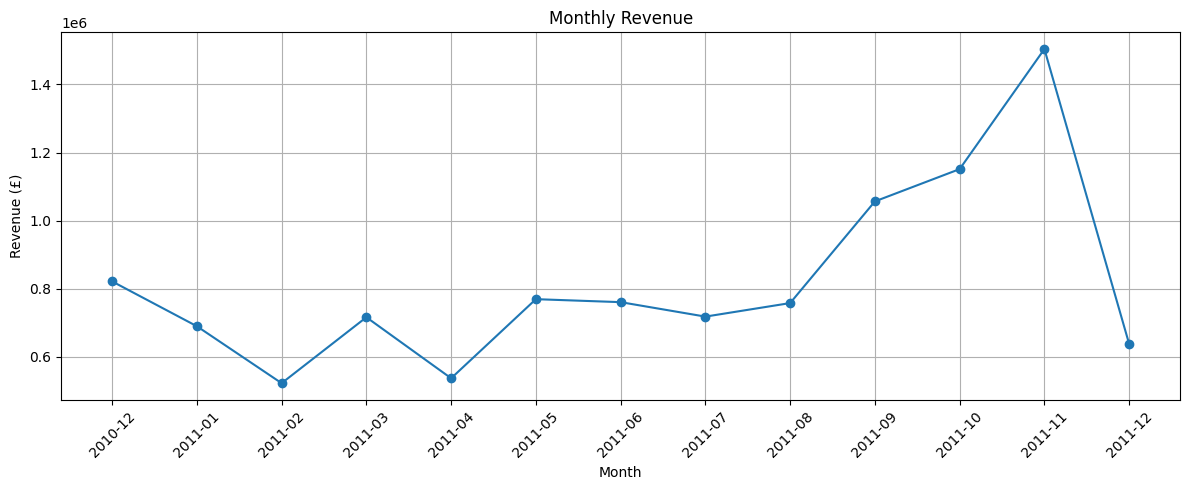

In [66]:
df_clean["Month"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

monthly_revenue = (
    df_clean.groupby("Month")["Revenue"]
    .sum()
    .reset_index().round(2)
)

print("\nMonthly Revenue:")
print(monthly_revenue)
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue["Month"].astype(str),
    monthly_revenue["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()


Top 10 Products by Quantity:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


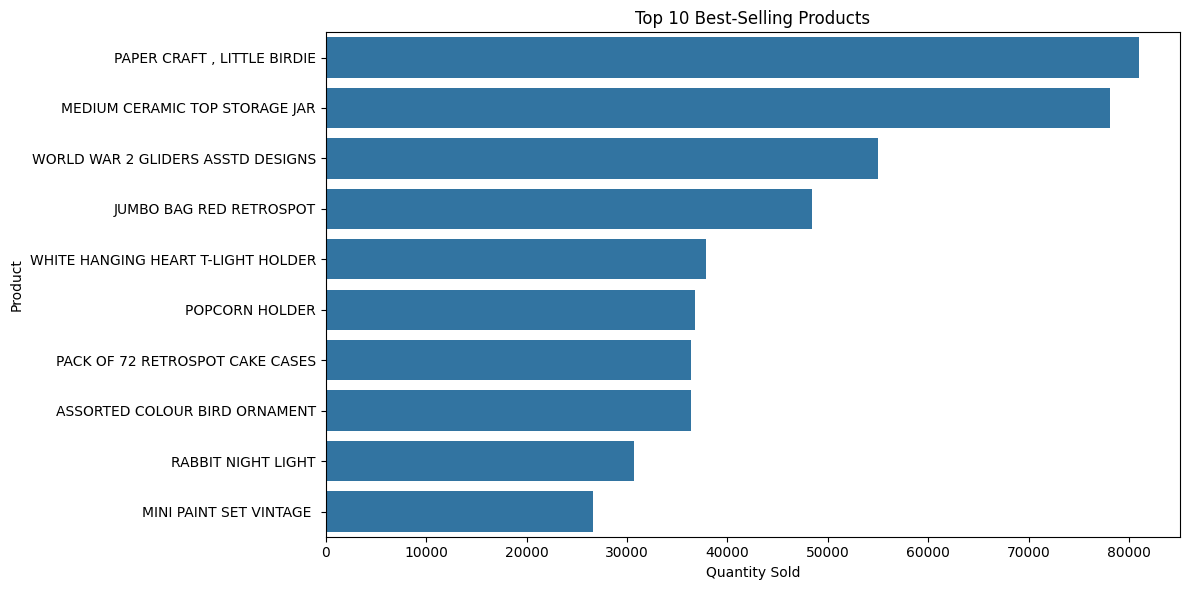

In [67]:
# top selling products
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print("\nTop 10 Products by Quantity:")
print(top_products)
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

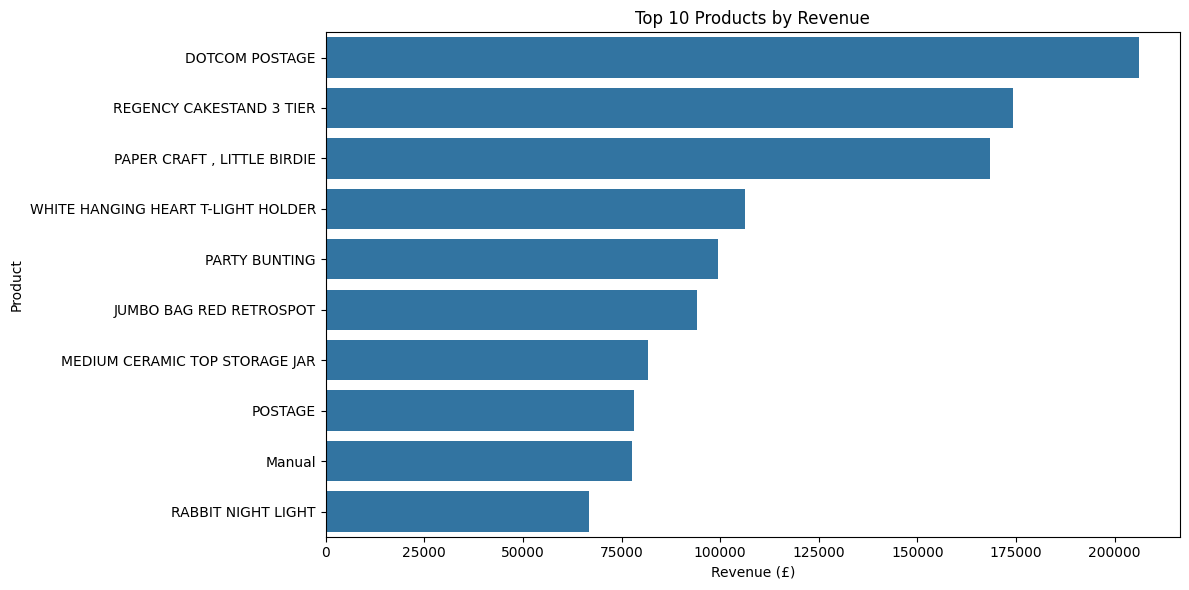

In [68]:
# Top 10 Products by Revenue

top_revenue_products = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_revenue_products.values,
    y=top_revenue_products.index
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [69]:
product_sales = df_clean[
    ~df_clean["Description"].str.contains(
        "POSTAGE|MANUAL",
        case=False,
        na=False
    )
]

top_actual_products = (
    product_sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_actual_products)

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64



Customer Purchase Frequency:
      CustomerID  PurchaseFrequency
326      12748.0                209
1879     14911.0                201
4010     17841.0                124
562      13089.0                 97
1661     14606.0                 93
2176     15311.0                 91
481      12971.0                 86
1689     14646.0                 73
2702     16029.0                 63
795      13408.0                 62


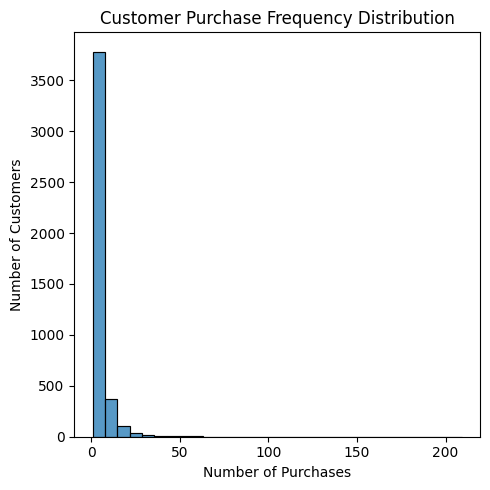

In [70]:
#customer purchase frequency
purchase_frequency = (
    customer_data.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reset_index()
)

purchase_frequency.columns = [
    "CustomerID",
    "PurchaseFrequency"
]

print("\nCustomer Purchase Frequency:")
top_customers = purchase_frequency.sort_values(
    by="PurchaseFrequency",
    ascending=False
).head(10)

print(top_customers)

plt.figure(figsize=(5, 5))

sns.histplot(
    data=purchase_frequency,
    x="PurchaseFrequency",
    bins=30
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


Revenue by Country:
          Country     Revenue
0  United Kingdom  9001744.09
1     Netherlands   285446.34
2            EIRE   283140.52
3         Germany   228678.40
4          France   209625.37
5       Australia   138453.81
6           Spain    61558.56
7     Switzerland    57067.60
8         Belgium    41196.34
9          Sweden    38367.83


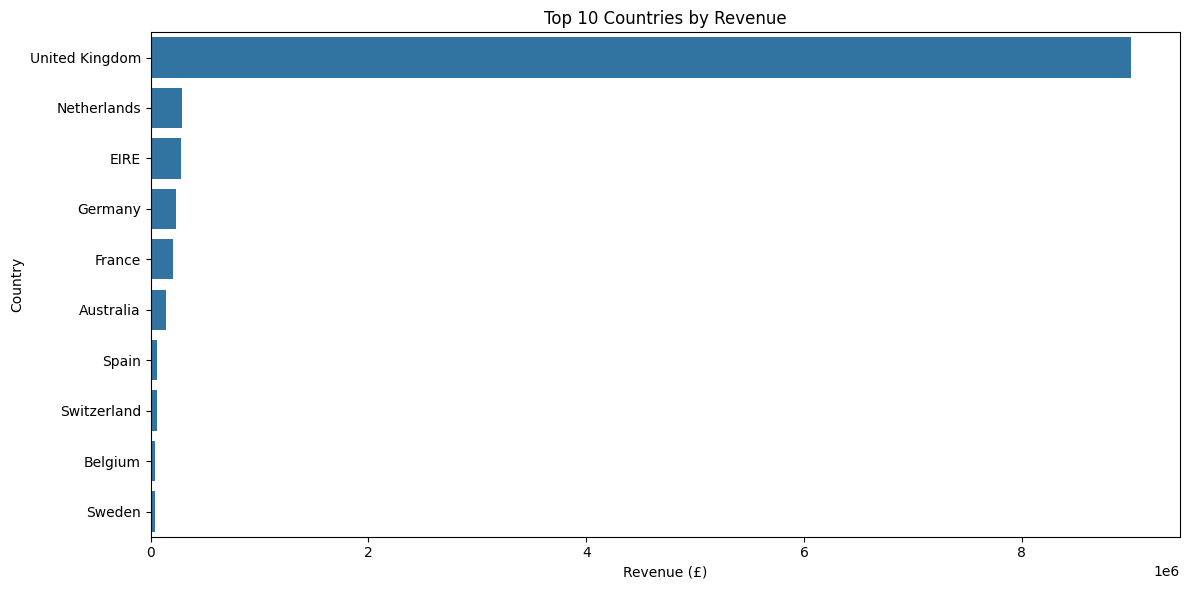

In [71]:
#Revenue by Country
country_revenue = (df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index().round(2)
)

print("\nRevenue by Country:")
print(country_revenue.head(10))

top_countries = country_revenue.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [72]:
total_revenue = df_clean["Revenue"].sum()

print("Total Revenue: £", round(total_revenue, 2))

print("Total Unique Customers:",customer_data["CustomerID"].nunique())

print("Total Unique Invoices:",df_clean["InvoiceNo"].nunique())

print("Total Products:",df_clean["StockCode"].nunique())

monthly_revenue.to_csv("Monthly_Revenue.csv", index=False)

purchase_frequency.to_csv("Purchase_Frequency.csv", index=False)

country_revenue.to_csv("Country_Revenue.csv", index=False)

Total Revenue: £ 10642110.8
Total Unique Customers: 4338
Total Unique Invoices: 19960
Total Products: 3922


In [73]:
#Module 3 : customer segmentation using RFM Analysis and K-Means Clustering
rfm_data=df_clean.dropna(subset=["CustomerID"]).copy()
rfm_data["Revenue"]=(rfm_data["Quantity"]*rfm_data["UnitPrice"])
print(rfm_data.shape)
rfm_data.head()

(392692, 10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


In [74]:
analysis_date = (rfm_data["InvoiceDate"].max()+ pd.Timedelta(days=1))
print("Analysis Date:", analysis_date)
rfm=rfm_data.groupby("CustomerID").agg({
    "InvoiceDate":lambda x:(analysis_date-x.max()).days,
    "InvoiceNo":"nunique","Revenue":"sum"
})
rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

print(rfm.head(10))
print(rfm.describe().round(2))

Analysis Date: 2011-12-10 12:50:00
            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40
12352.0          36          8   2506.04
12353.0         204          1     89.00
12354.0         232          1   1079.40
12355.0         214          1    459.40
12356.0          23          3   2811.43
       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2048.69
std     100.01       7.70    8985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00    1660.60
max     374.00     209.00  280206.02


In [75]:
print("total customers :",len(rfm))

total customers : 4338


In [85]:
import numpy as np
from sklearn.preprocessing import StandardScaler
rfm_log = np.log1p(rfm)

print(rfm_log.head())
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

             Recency  Frequency   Monetary
CustomerID                                
12346.0     5.789960   0.693147  11.253955
12347.0     1.098612   2.079442   8.368925
12348.0     4.330733   1.609438   7.494564
12349.0     2.995732   0.693147   7.472245
12350.0     5.739793   0.693147   5.815324


In [77]:
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm.index
)

print(rfm_scaled.head())

             Recency  Frequency  Monetary
CustomerID                               
12346.0     1.461993  -0.955214  3.707716
12347.0    -2.038734   1.074425  1.414903
12348.0     0.373104   0.386304  0.720024
12349.0    -0.623086  -0.955214  0.702287
12350.0     1.424558  -0.955214 -0.614514


In [78]:
print("Feature Means:")
print(rfm_scaled.mean())

print("\nFeature Standard Deviations:")
print(rfm_scaled.std())

Feature Means:
Recency     -9.172520e-17
Frequency   -7.206980e-17
Monetary    -3.669008e-16
dtype: float64

Feature Standard Deviations:
Recency      1.000115
Frequency    1.000115
Monetary     1.000115
dtype: float64


In [87]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

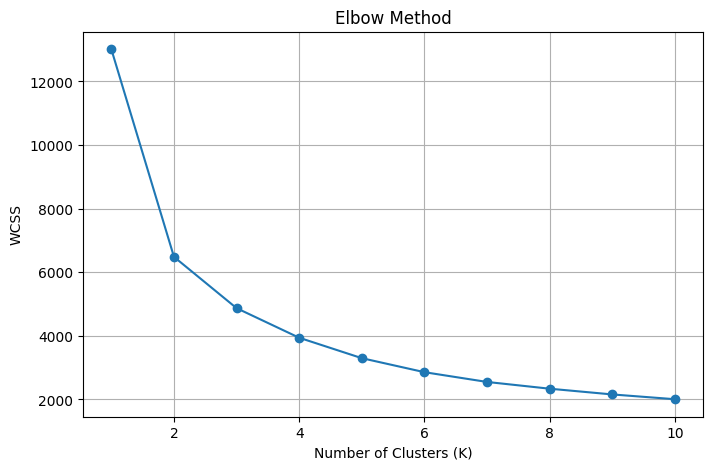

In [88]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid(True)

plt.show()

In [89]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

In [90]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

print("Customers in each cluster:")
print(cluster_counts)

Customers in each cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [92]:
cluster_analysis = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)
cluster_analysis["CustomerCount"] = (
    rfm.groupby("Cluster").size()
)

print(cluster_analysis)


         Recency  Frequency  Monetary  CustomerCount
Cluster                                             
0          12.17      13.75   8088.02            713
1         181.51       1.32    341.00           1622
2          17.70       2.19    557.32            837
3          71.64       4.08   1801.78           1166


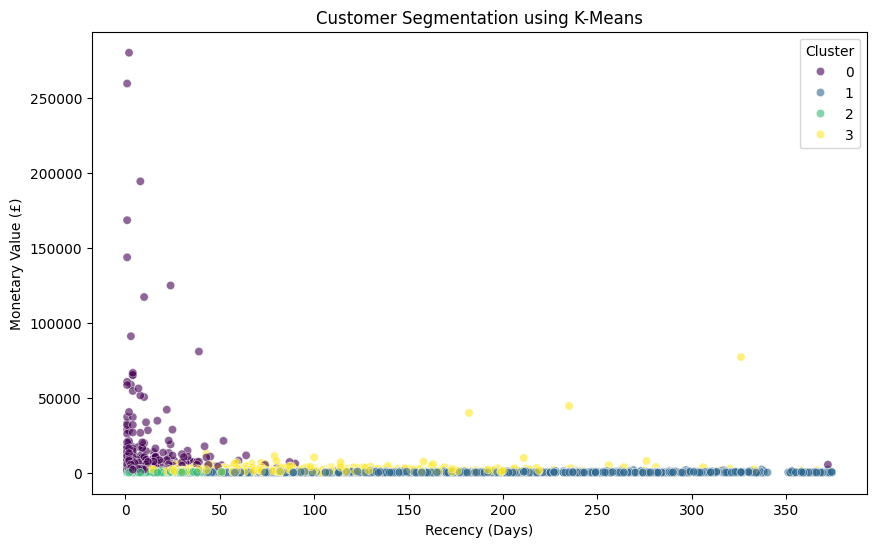

In [93]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.6
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (£)")
plt.legend(title="Cluster")

plt.show()

In [94]:
cluster_profile = rfm.groupby("Cluster").agg(
    CustomerCount=("Recency", "size"),

    Recency_mean=("Recency", "mean"),
    Recency_median=("Recency", "median"),

    Frequency_mean=("Frequency", "mean"),
    Frequency_median=("Frequency", "median"),

    Monetary_mean=("Monetary", "mean"),
    Monetary_median=("Monetary", "median")
).round(2)

print(cluster_profile)

         CustomerCount  Recency_mean  Recency_median  Frequency_mean  \
Cluster                                                                
0                  713         12.17             8.0           13.75   
1                 1622        181.51           174.5            1.32   
2                  837         17.70            17.0            2.19   
3                 1166         71.64            57.0            4.08   

         Frequency_median  Monetary_mean  Monetary_median  
Cluster                                                    
0                    10.0        8088.02          3722.82  
1                     1.0         341.00           296.09  
2                     2.0         557.32           480.31  
3                     4.0        1801.78          1345.20  
